# 03 · Evaluating the models on live Instagram data

The six models from notebook 01 (LogReg, RF and XGBoost, each trained on 50/50 and on 90/10 Kaggle data) score the hand-labeled live sample from notebook 02. This notebook asks:
1. How well do they do on live data, and with what uncertainty? (stratified bootstrap CIs)
2. Does the ranking quality (PR curves) carry over from Kaggle?
3. Which genuine accounts get wrongly flagged, and why? (error analysis and feature shift)

This notebook is self-contained: all code is defined here. No usernames are shown.

In [1]:
from pathlib import Path
import os
# Run from the project root (the folder that holds data/ and models/), wherever Jupyter was started.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
os.chdir(ROOT)

In [2]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
N_BOOT = 1000
SEED = 0
NAMES = {"logreg": "LogReg", "rf": "RF", "xgb": "XGBoost"}
CFG = {"balanced": "50/50", "imbalanced": "90/10"}

In [3]:
# The 11 features, named as in the Kaggle "Instagram Fake Spammer Genuine Accounts" files.
FEATURES = [
    "profile pic",           # 1 if the account has a (non-default) profile picture
    "nums/length username",  # share of digits in the username
    "fullname words",        # number of words in the full name
    "nums/length fullname",  # share of digits in the full name
    "name==username",        # 1 if full name equals username
    "description length",    # characters in the bio
    "external URL",          # 1 if the profile has an external link
    "private",               # 1 if the account is private
    "#posts",
    "#followers",
    "#follows",
]
LABEL = "fake"  # 1 = fake, 0 = genuine
COUNT_FEATURES = ["description length", "#posts", "#followers", "#follows"]

In [4]:
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)


def evaluate(y_true, prob, threshold=0.5) -> dict:
    """Metrics for the fake class (positive = 1)."""
    y_true = np.asarray(y_true)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        "threshold": threshold,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob) if both else np.nan,
        "pr_auc": average_precision_score(y_true, prob) if both else np.nan,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "fpr": fp / (fp + tn) if fp + tn else np.nan,
    }

## 1. Data and models

In [5]:
raw_live = pd.read_csv("data/live_labeled.csv")
live = raw_live.dropna(subset=[LABEL]).reset_index(drop=True)
live[LABEL] = live[LABEL].astype(int)
y = live[LABEL].to_numpy()
kag_train = pd.read_csv("data/train.csv")
kag_test = pd.read_csv("data/test.csv")
print(f"live: {len(raw_live)} collected, {len(live)} labeled, {y.sum()} fake ({y.mean():.1%})")

models = {}
for path in sorted(Path("models").glob("*.joblib")):
    meta = json.loads(path.with_name(path.stem + ".meta.json").read_text())
    models[path.stem] = (joblib.load(path), meta)

def label(stem):
    cfg, name = stem.split("_", 1)
    return f"{NAMES[name]} ({CFG[cfg]})"

probs = {k: m.predict_proba(live[FEATURES])[:, 1] for k, (m, _) in models.items()}
kprobs = {k: m.predict_proba(kag_test[FEATURES])[:, 1] for k, (m, _) in models.items()}
pd.DataFrame([{"model": label(k), "tuned threshold": meta["tuned_threshold"],
               "train rows": meta["n_train"], "train fake share": meta["fake_share_train"]}
              for k, (_, meta) in models.items()])

live: 239 collected, 239 labeled, 14 fake (5.9%)


,model,tuned threshold,train rows,train fake share
0,LogReg (50/50),0.43,574,0.500000
1,RF (50/50),0.41,574,0.500000
2,XGBoost (50/50),0.62,574,0.500000
3,LogReg (90/10),0.68,319,0.100313
4,RF (90/10),0.54,319,0.100313
5,XGBoost (90/10),0.85,319,0.100313


## 2. Live results at default and tuned thresholds

In [6]:
rows = []
for k, (_, meta) in models.items():
    cfg, name = k.split("_", 1)
    for kind, t in [("default_0.5", 0.5), ("tuned", meta["tuned_threshold"])]:
        rows.append({"model": name, "trained_on": cfg, "threshold_type": kind, **evaluate(y, probs[k], t)})
live_res = pd.DataFrame(rows).round(3)
live_res[["model", "trained_on", "threshold_type", "threshold", "precision", "recall", "f1",
          "roc_auc", "pr_auc", "tp", "fp", "fn", "tn"]]

,model,trained_on,threshold_type,threshold,precision,recall,f1,roc_auc,pr_auc,tp,fp,fn,tn
0,logreg,balanced,default_0.5,0.50,0.130,1.000,0.230,0.977,0.763,14,94,0,131
1,logreg,balanced,tuned,0.43,0.124,1.000,0.220,0.977,0.763,14,99,0,126
2,rf,balanced,default_0.5,0.50,0.169,1.000,0.289,0.958,0.636,14,69,0,156
3,rf,balanced,tuned,0.41,0.149,1.000,0.259,0.958,0.636,14,80,0,145
4,xgb,balanced,default_0.5,0.50,0.141,1.000,0.248,0.976,0.765,14,85,0,140
5,xgb,balanced,tuned,0.62,0.171,1.000,0.292,0.976,0.765,14,68,0,157
6,logreg,imbalanced,default_0.5,0.50,0.184,1.000,0.311,0.967,0.724,14,62,0,163
7,logreg,imbalanced,tuned,0.68,0.264,1.000,0.418,0.967,0.724,14,39,0,186
8,rf,imbalanced,default_0.5,0.50,0.244,0.786,0.373,0.934,0.560,11,34,3,191
9,rf,imbalanced,tuned,0.54,0.256,0.786,0.386,0.934,0.560,11,32,3,193


## 3. Bootstrap 95% confidence intervals (threshold 0.5)
With only 14 fakes, point estimates are noisy. The **stratified** bootstrap resamples fakes and genuines separately, with replacement, so every resample keeps the 5.9% base rate. All models use the same resamples, and the 2.5th and 97.5th percentiles give the interval. When a model catches every fake, every resample does too, so its recall interval collapses to [1.00–1.00]. That is a limit of the bootstrap with 14 fakes, not certainty.

In [7]:
def point_metrics(yt, p, t=0.5):
    pred = (p >= t).astype(int)
    return {"precision": precision_score(yt, pred, zero_division=0),
            "recall": recall_score(yt, pred, zero_division=0),
            "f1": f1_score(yt, pred, zero_division=0),
            "pr_auc": average_precision_score(yt, p)}


def bootstrap_ci(yt, probs, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(yt == 1)[0], np.where(yt == 0)[0]
    draws = {k: [] for k in probs}
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        for k, p in probs.items():
            draws[k].append(point_metrics(yt[idx], p[idx]))
    out = []
    for k, p in probs.items():
        est, d = point_metrics(yt, p), pd.DataFrame(draws[k])
        for m in est:
            lo, hi = np.percentile(d[m], [2.5, 97.5])
            out.append({"model": k, "metric": m, "estimate": est[m], "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(out)

ci = bootstrap_ci(y, probs)

In [8]:
# Side-by-side with the Kaggle 90/10 results (mean over 10 seeds, threshold 0.5, from notebook 01).
summ = pd.read_csv("results/summary.csv")
side = []
for k in models:
    cfg, name = k.split("_", 1)
    s = summ[(summ.model == name) & (summ.trained_on == cfg) & (summ.test_set == "imbalanced_test")
             & (summ.threshold_type == "default_0.5")].iloc[0]
    c = ci[ci.model == k].set_index("metric")
    f = lambda m: f"{c.loc[m, 'estimate']:.2f} [{c.loc[m, 'ci_low']:.2f}–{c.loc[m, 'ci_high']:.2f}]"
    side.append({"Model": label(k),
                 "Kaggle 90/10 P / R / F1": f"{s.precision_mean:.2f} / {s.recall_mean:.2f} / {s.f1_mean:.2f}",
                 "Kaggle 90/10 PR-AUC": f"{s.pr_auc_mean:.2f}",
                 "Live precision": f("precision"), "Live recall": f("recall"),
                 "Live F1": f("f1"), "Live PR-AUC": f("pr_auc"),
                 "Live FP / genuine": f"{int(((probs[k] >= 0.5) & (y == 0)).sum())} / {(y == 0).sum()}"})
pd.DataFrame(side)

,Model,Kaggle 90/10 P / R / F1,Kaggle 90/10 PR-AUC,Live precision,Live recall,Live F1,Live PR-AUC,Live FP / genuine
0,LogReg (50/50),0.49 / 0.97 / 0.65,0.89,0.13 [0.11–0.15],1.00 [1.00–1.00],0.23 [0.21–0.26],0.76 [0.58–0.94],94 / 225
1,RF (50/50),0.61 / 0.90 / 0.73,0.93,0.17 [0.15–0.20],1.00 [1.00–1.00],0.29 [0.25–0.33],0.64 [0.43–0.86],69 / 225
2,XGBoost (50/50),0.58 / 0.97 / 0.72,0.95,0.14 [0.12–0.16],1.00 [1.00–1.00],0.25 [0.22–0.28],0.77 [0.59–0.93],85 / 225
3,LogReg (90/10),0.61 / 0.89 / 0.71,0.87,0.18 [0.16–0.22],1.00 [1.00–1.00],0.31 [0.27–0.36],0.72 [0.52–0.92],62 / 225
4,RF (90/10),0.74 / 0.73 / 0.71,0.87,0.24 [0.17–0.33],0.79 [0.57–1.00],0.37 [0.26–0.49],0.56 [0.35–0.79],34 / 225
5,XGBoost (90/10),0.83 / 0.70 / 0.74,0.89,0.24 [0.20–0.30],1.00 [1.00–1.00],0.39 [0.33–0.46],0.59 [0.40–0.79],44 / 225


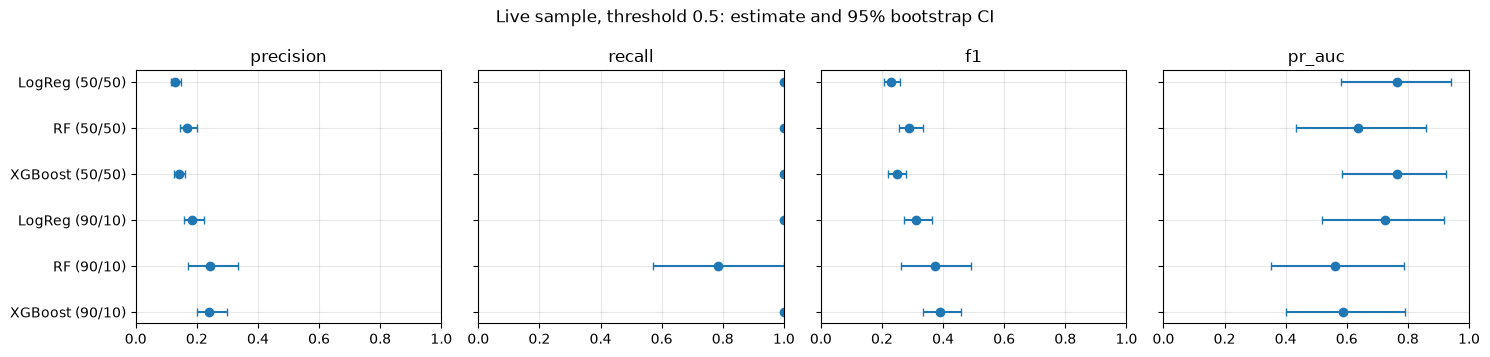

In [9]:
# The same intervals as a chart.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
order = list(models)
for ax, m in zip(axes, ["precision", "recall", "f1", "pr_auc"]):
    c = ci[ci.metric == m].set_index("model").loc[order]
    ax.errorbar(c.estimate, range(len(order)), xerr=[c.estimate - c.ci_low, c.ci_high - c.estimate],
                fmt="o", color="#1f77b4", capsize=3)
    ax.set(title=m, xlim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].set_yticks(range(len(order)), [label(k) for k in order])
axes[0].invert_yaxis()
fig.suptitle("Live sample, threshold 0.5: estimate and 95% bootstrap CI")
fig.tight_layout()

## 4. Precision–recall curves: live vs Kaggle
The dotted line is the base rate, where a random ranking would sit. The Kaggle panel uses the official `test.csv` (50/50), so its base rate is 50%.

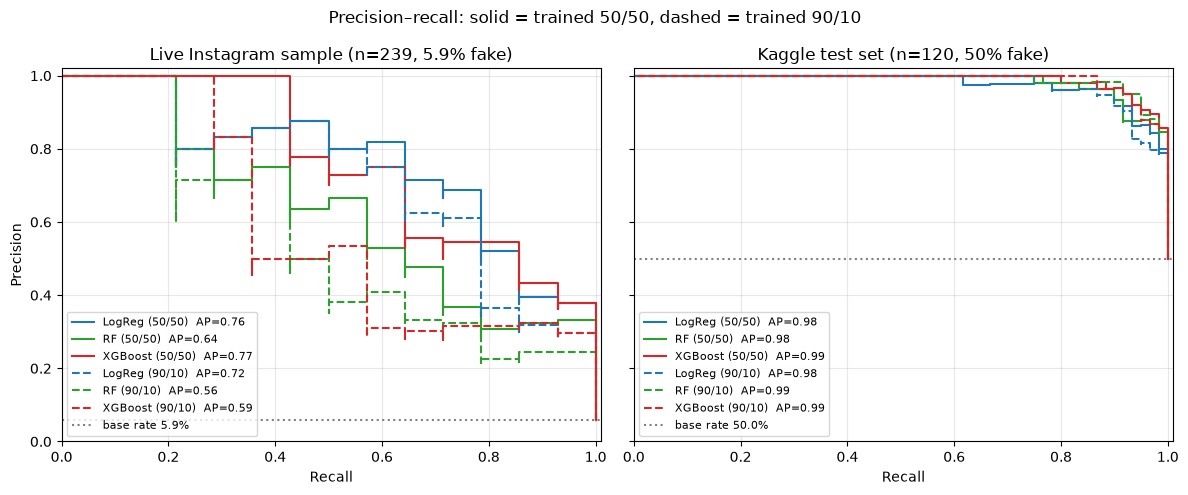

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
colors = {"logreg": "#1f77b4", "rf": "#2ca02c", "xgb": "#d62728"}
for ax, (title, yt, pr) in zip(axes, [
        (f"Live Instagram sample (n={len(y)}, {y.mean():.1%} fake)", y, probs),
        (f"Kaggle test set (n={len(kag_test)}, {kag_test[LABEL].mean():.0%} fake)",
         kag_test[LABEL].to_numpy(), kprobs)]):
    for k, p in pr.items():
        cfg, name = k.split("_", 1)
        prec, rec, _ = precision_recall_curve(yt, p)
        ax.step(rec, prec, where="post", color=colors[name], ls="-" if cfg == "balanced" else "--",
                label=f"{label(k)}  AP={average_precision_score(yt, p):.2f}")
    ax.axhline(yt.mean(), color="grey", ls=":", label=f"base rate {yt.mean():.1%}")
    ax.set(title=title, xlabel="Recall", xlim=(0, 1.01), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc="lower left")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Precision")
fig.suptitle("Precision–recall: solid = trained 50/50, dashed = trained 90/10")
fig.tight_layout()

## 5. Why the drop? Feature shift between Kaggle and live data
Medians and shares per class. "Kaggle" here is `train.csv`.

In [11]:
def describe(df):
    return {
        "n": len(df),
        "median #posts": df["#posts"].median(),
        "median #followers": df["#followers"].median(),
        "median #follows": df["#follows"].median(),
        "median follows/followers": (df["#follows"] / df["#followers"].clip(lower=1)).median(),
        "median description length": df["description length"].median(),
        "median fullname words": df["fullname words"].median(),
        "% private": 100 * df["private"].mean(),
        "% no profile pic": 100 * (1 - df["profile pic"].mean()),
        "% external URL": 100 * df["external URL"].mean(),
        "% name==username": 100 * df["name==username"].mean(),
        "% username has digits": 100 * (df["nums/length username"] > 0).mean(),
        "mean digit share username": df["nums/length username"].mean(),
        "% 0 posts": 100 * (df["#posts"] == 0).mean(),
        "% empty bio": 100 * (df["description length"] == 0).mean(),
    }

shift = pd.DataFrame({
    "Kaggle genuine": describe(kag_train[kag_train[LABEL] == 0]),
    "live genuine": describe(live[y == 0]),
    "Kaggle fake": describe(kag_train[kag_train[LABEL] == 1]),
    "live fake": describe(live[y == 1]),
}).round(2)
shift

,Kaggle genuine,live genuine,Kaggle fake,live fake
n,288.00,225.00,288.00,14.00
median #posts,74.00,44.00,0.00,0.00
median #followers,661.50,229.00,40.00,0.50
median #follows,431.00,603.00,70.00,568.00
median follows/followers,0.90,2.99,2.28,47.80
median description length,27.00,17.00,0.00,0.00
median fullname words,2.00,2.00,1.00,0.50
% private,39.58,39.11,36.81,42.86
% no profile pic,0.69,3.11,59.03,64.29
% external URL,23.26,15.11,0.00,0.00


## 6. Error analysis: which genuine accounts get flagged?
False positives (FP: genuine accounts with P(fake) ≥ 0.5) of XGBoost (50/50) and LogReg (90/10), compared with the correctly passed genuine accounts (TN), all live genuine accounts, live fakes, and both Kaggle classes.

In [12]:
groups = {}
for k in ["balanced_xgb", "imbalanced_logreg"]:
    pred = probs[k] >= 0.5
    groups[f"FP {label(k)}"] = live[pred & (y == 0)]
    groups[f"TN {label(k)}"] = live[~pred & (y == 0)]
groups["live genuine (all)"] = live[y == 0]
groups["live fake"] = live[y == 1]
groups["Kaggle genuine"] = kag_train[kag_train[LABEL] == 0]
groups["Kaggle fake"] = kag_train[kag_train[LABEL] == 1]
err = pd.DataFrame({g: describe(d) for g, d in groups.items()}).round(2)
err

,FP XGBoost (50/50),TN XGBoost (50/50),FP LogReg (90/10),TN LogReg (90/10),live genuine (all),live fake,Kaggle genuine,Kaggle fake
n,85.00,140.00,62.00,163.00,225.00,14.00,288.00,288.00
median #posts,3.00,181.50,1.00,111.00,44.00,0.00,74.00,0.00
median #followers,43.00,406.00,39.50,344.00,229.00,0.50,661.50,40.00
median #follows,271.00,822.00,176.00,894.00,603.00,568.00,431.00,70.00
median follows/followers,6.65,1.73,5.87,2.20,2.99,47.80,0.90,2.28
median description length,0.00,54.00,0.00,34.00,17.00,0.00,27.00,0.00
median fullname words,1.00,2.00,2.00,2.00,2.00,0.50,2.00,1.00
% private,37.65,40.00,19.35,46.63,39.11,42.86,39.58,36.81
% no profile pic,8.24,0.00,11.29,0.00,3.11,64.29,0.69,59.03
% external URL,2.35,22.86,1.61,20.25,15.11,0.00,23.26,0.00


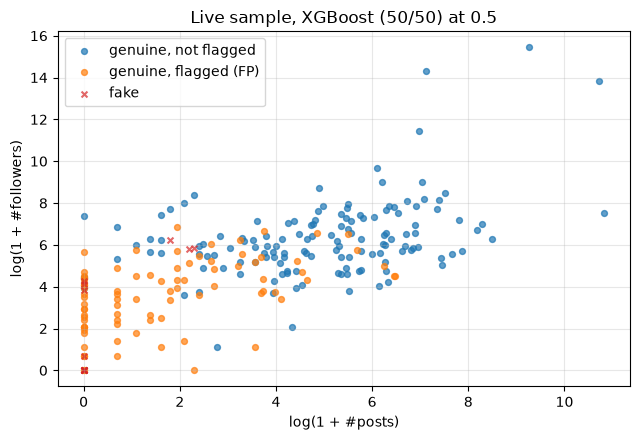

In [13]:
# Where do the false positives sit? Followers vs posts for live genuine accounts.
k = "balanced_xgb"
fp = (probs[k] >= 0.5) & (y == 0)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for mask, name, c, mk in [((y == 0) & ~fp, "genuine, not flagged", "#1f77b4", "o"),
                          (fp, "genuine, flagged (FP)", "#ff7f0e", "o"),
                          (y == 1, "fake", "#d62728", "x")]:
    ax.scatter(np.log1p(live.loc[mask, "#posts"]), np.log1p(live.loc[mask, "#followers"]),
               s=18, alpha=0.7, color=c, marker=mk, label=name)
ax.set(xlabel="log(1 + #posts)", ylabel="log(1 + #followers)", title=f"Live sample, {label(k)} at 0.5")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

## 7. Accounts that disappeared after collection
An account that is deleted or suspended soon after collection is extra evidence it was fake (see the labeling rubric).

In [14]:
if "gone" in raw_live.columns or "status" in raw_live.columns:
    gone_mask = (raw_live["gone"].fillna(0).astype(float) == 1) if "gone" in raw_live.columns \
        else (raw_live["status"] == "gone")
    gone = raw_live[gone_mask]
    print(f"accounts marked gone: {len(gone)} ({gone[LABEL].notna().sum()} labeled)")
    if len(gone):
        print("all-zero features:", bool((gone[FEATURES] == 0).all(axis=1).all()))
        display(pd.DataFrame([{"model": label(k), "mean P(fake)": m.predict_proba(gone[FEATURES])[:, 1].mean(),
                               "share flagged at 0.5": (m.predict_proba(gone[FEATURES])[:, 1] >= 0.5).mean()}
                              for k, (m, _) in models.items()]).round(2))
else:
    print("no gone/status column")

accounts marked gone: 1 (1 labeled)
all-zero features: True


,model,mean P(fake),share flagged at 0.5
0,LogReg (50/50),1.00,1.0
1,RF (50/50),0.99,1.0
2,XGBoost (50/50),1.00,1.0
3,LogReg (90/10),0.99,1.0
4,RF (90/10),0.99,1.0
5,XGBoost (90/10),1.00,1.0


Only one account is marked `gone`. It is now labeled fake, but the scrape returned nothing for it, so all its features are 0. Every model gives it P(fake) ≈ 1, which reflects the empty record, not evidence about the account. It is one of the 14 live fakes, so it adds one easy true positive for every model. The planned recheck of fake-labeled accounts 2–3 weeks after collection is still to do.

## 8. Findings
- **The models still rank live accounts well, but the base rate is low.** Live ROC-AUC is 0.93–0.98, close to the Kaggle 90/10 test sets (0.98–0.99). Live PR-AUC is 0.56–0.77, against 0.87–0.95 on Kaggle 90/10. Part of that gap is the lower base rate (5.9% fake vs 10%), which pulls PR-AUC down even for the same ranking quality.
- **Recall survives; precision collapses.** Five of the six models catch all 14 fakes at 0.5 (RF 90/10 catches 11). But the 50/50 models flag 69–94 of the 225 genuine accounts (31–42%), so their precision is only 0.13–0.17. The 90/10 models flag fewer genuine accounts (34–62) and reach precision 0.18–0.24.
- **Training at the realistic ratio helps on live data.** XGBoost (90/10) has the best F1 at 0.5 (0.39, CI 0.33–0.46), with full recall and 44 false positives. Its precision CI (0.20–0.30) and F1 CI do not overlap those of LogReg (50/50) and XGBoost (50/50). XGBoost (50/50) and LogReg (50/50) still have the best PR-AUC (0.77 and 0.76): they rank well, but 0.5 is far too loose a threshold for a 5.9% base rate.
- **Tuned thresholds help a little.** LogReg (90/10) at its tuned 0.68 cuts false positives from 62 to 39 and keeps recall at 1.00 (precision 0.26, F1 0.42, the best of any configuration). XGBoost (90/10) at 0.85 has the fewest false positives (25) but misses 4 of 14 fakes. No tuned threshold gets precision above 0.29.
- **The cause is domain shift in the genuine class.** Live genuine accounts are much less "active" than Kaggle genuine accounts: median followers 229 vs 662, follows/followers 3.0 vs 0.9, 14% with zero posts vs 1.4%, 39% with digits in the username vs 19%, and 42% with an empty bio vs 27%. Each of these moves them toward what the models learned as "fake".
- **The false positives are low-activity genuine users.** The genuine accounts XGBoost (50/50) flags have a median of 3 posts and 43 followers. 32% have zero posts, 59% have digits in the username and 67% have an empty bio, which is close to the Kaggle fake profile. The LogReg (90/10) false positives look the same (median 1 post, 40 followers, 40% zero posts). The 11 features cannot tell a lurker or new real user from a spam account.
- **Live fakes look like Kaggle fakes, except that they follow many accounts.** 64% lack a profile picture (59% in Kaggle), 79% have zero posts (53%) and 93% have an empty bio (86%), so they are empty shells that the models catch easily. The difference is follows: median 568 vs 70, with a median of 0.5 followers.
- **Takeaway:** the fake side of Kaggle transfers to live data; the genuine side does not. Training on 90/10 data and raising the threshold reduce false positives, but at a 5.9% base rate even the best configuration flags about 2.8 genuine accounts per fake caught (39 FP vs 14 TP). A usable model would need genuine training data from the target population, or richer features (post content, comment behaviour, account age).

## 9. Limitations
- **One labeler.** All labels are one person's judgment from public profiles, so there is no inter-annotator agreement (no Cohen's kappa). Low-activity accounts, exactly where the models disagree with the labels, are the hardest to judge.
- **Full coverage.** All 239 collected profiles are labeled, including the 18 that an earlier pass left blank as too uncertain. No hard cases are dropped, but those labels are the least certain.
- **Sampling.** Profiles are commenters on a handful of seed posts, so the sample reflects those posts' audiences, not Instagram overall.
- **Private accounts.** About 39% are private, so the labeler saw only the profile header.
- **Few fakes.** Only 14 fakes, so recall and PR-AUC CIs are wide (e.g. XGBoost 50/50 PR-AUC 0.59–0.93), and catching all 14 is consistent with a true recall as low as about 0.8. One of the 14 is the `gone` account with an empty record. Small differences between models are not meaningful.